# **Project Summary**

Estimating the Remaining Useful Life (RUL) of equipment has been a primary focus of predictive maintenance. This is especially critical in the aviation industry, where an inaccurate prediction can result in unexpected in-flight engine shutdowns leading to severe flight-safety hazards. On the other hand, over-servicing healthy engines wastes valuable operational flight hours and maintenance resources. The primary objective of this project is to estimate the Remaining Useful Life of critical turbofan engine components under complex, multi-regime operating conditions prior to functional failure.

Models are developed and validated using the NASA C-MAPSS FD002 dataset. Unlike the single sea-level operating environment of FD001, FD002 introduces six distinct flight operating regimes—driven by variations in altitude, Mach number, and throttle resolver angles—which induce massive sensor fluctuations that mask underlying mechanical degradation. The dataset consists of 260 training engines run to failure and 259 test engines truncated at arbitrary cycles prior to failure. We implement an unsupervised K-Means clustering and regime-specific Z-score normalization strategy to isolate true physical wear anomalies. We  benchmarked classical linear and gradient-boosted tree baselines against deep sequence architectures (Stacked LSTM, 1D-CNN) while evaluating both symmetric error metrics (RMSE/MAE) and the asymmetric NASA operational scoring function.

The end-to-end workflow is structured into six distinct sections:

1. **Exploratory Data Analysis & Unsupervised Operating Regime Clustering (K-Means)**

2. **Target Engineering (Piecewise RUL Formulation)**

3. **Classical Machine Learning Baselines (Rolling Feature Engineering & Tabular Models)**

4. **Deep Sequence Modeling (Stacked LSTM & 1D-CNN)**

5. **Engine-Level Cross-Validation (5-Fold GroupKFold) & Benchmark Leaderboard**

6. **Operational Decision Matrix & Interactive Deployment Dashboard**

In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="threadpoolctl")
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import os

from sklearn.cluster import KMeans

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge, RidgeCV
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM, Conv1D, MaxPooling1D, Flatten, GlobalAveragePooling1D, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler

import time
from sklearn.base import clone
from tqdm import tqdm

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import subprocess
from IPython.display import IFrame


### **Section 1: Exploratory Data Analysis & Unsupervised Operating Regime Clustering (K-Means)**

In [2]:
DATA_DIR = Path('../data')
INDEX_COLS = ['unit_nr', 'time_cycles']
SETTING_COLS = ['setting_1', 'setting_2', 'setting_3']
SENSOR_COLS = [f"sensor_{i}" for i in range(1,22)]
COLUMN_NAMES = INDEX_COLS + SETTING_COLS + SENSOR_COLS

In [3]:
df = pd.read_csv(DATA_DIR/'train_FD002.txt', sep = r'\s+', header = None, names = COLUMN_NAMES)
df.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


### Column Definitions

The C-MAPSS simulation instruments a high-bypass turbofan engine with 3 operational condition controls and 21 health-monitoring sensor channels:

#### Operational Settings (Flight Regimes)
* **`setting_1`**: Flight Altitude ($0 \text{ to } 42 \times 10^3\text{ ft}$)
* **`setting_2`**: Flight Mach Number ($0.0 \text{ to } 0.84\text{ Mach}$)
* **`setting_3`**: Throttle Resolver Angle (TRA / Power Demand, typically $60 \text{ to } 100$)

#### Monitored Sensor Channels
| Channel | Parameter | Physical Description | Engineering Units |
| :--- | :--- | :--- | :--- |
| `sensor_1` | $T_2$ | Total temperature at fan inlet | $^\circ\text{R}$ |
| `sensor_2` | $T_{24}$ | Total temperature at LPC outlet | $^\circ\text{R}$ |
| `sensor_3` | $T_{30}$ | Total temperature at HPC outlet | $^\circ\text{R}$ |
| `sensor_4` | $T_{50}$ | Total temperature at LPT outlet | $^\circ\text{R}$ |
| `sensor_5` | $P_2$ | Pressure at fan inlet | $\text{psia}$ |
| `sensor_6` | $P_{15}$ | Total pressure in bypass duct | $\text{psia}$ |
| `sensor_7` | $P_{30}$ | Total pressure at HPC outlet | $\text{psia}$ |
| `sensor_8` | $N_f$ | Physical fan speed | $\text{rpm}$ |
| `sensor_9` | $N_c$ | Physical core speed | $\text{rpm}$ |
| `sensor_10` | $epr$ | Engine pressure ratio ($P_{50} / P_2$) | — |
| `sensor_11` | $Ps_{30}$ | Static pressure at HPC outlet | $\text{psia}$ |
| `sensor_12` | $\phi$ | Fuel flow ratio to static pressure ($W_f / Ps_{30}$) | $\text{pps/psia}$ |
| `sensor_13` | $NR_f$ | Corrected fan speed | $\text{rpm}$ |
| `sensor_14` | $NR_c$ | Corrected core speed | $\text{rpm}$ |
| `sensor_15` | $BPR$ | Bypass ratio | — |
| `sensor_16` | $farB$ | Burner fuel-air ratio | — |
| `sensor_17` | $htBleed$ | Bleed enthalpy | — |
| `sensor_18` | $Nf\_dmd$ | Demanded fan speed | $\text{rpm}$ |
| `sensor_19` | $PCNfR\_dmd$ | Demanded corrected fan speed | $\text{rpm}$ |
| `sensor_20` | $W_{31}$ | High-Pressure Turbine (HPT) coolant bleed | $\text{lbm/s}$ |
| `sensor_21` | $W_{32}$ | Low-Pressure Turbine (LPT) coolant bleed | $\text{lbm/s}$ |

### Since there are different operating regimes in FD002 which are captured by the three setting columns describing altitude, Mach number, and throttle resolver angles. It is important to identify these regimes and normalize the sensor values corresponding to each flight regime. 

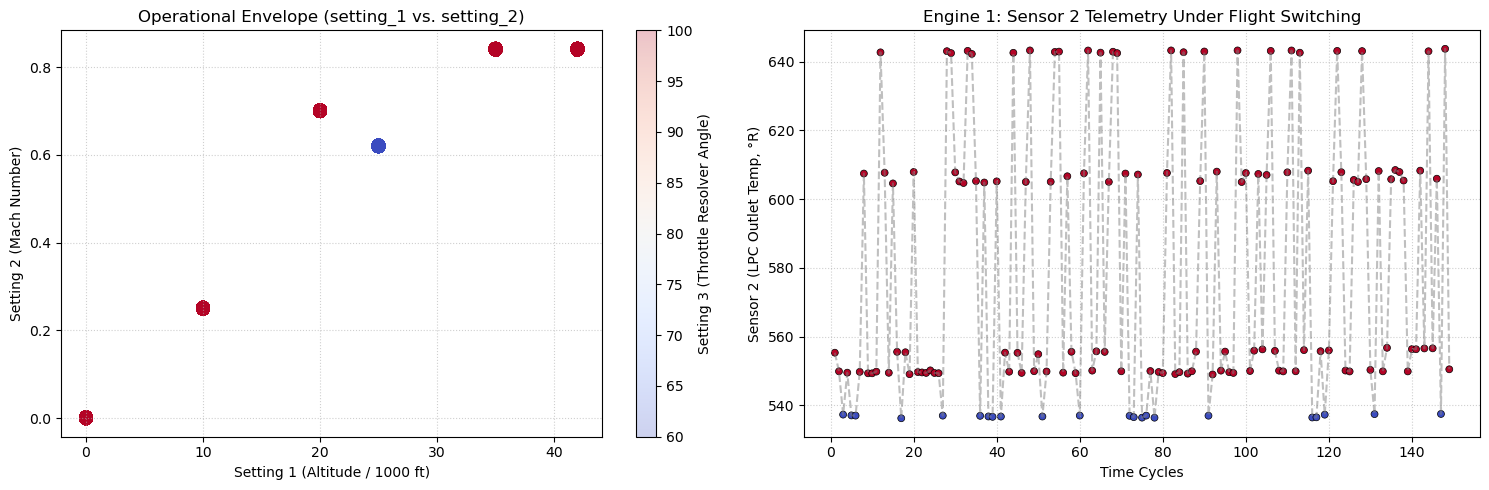

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Operational Flight Envelope: Shows 6 natural clusters before running K-Means
scatter = axes[0].scatter(
    df['setting_1'], 
    df['setting_2'], 
    c=df['setting_3'], 
    cmap='coolwarm', 
    alpha=0.25, 
    s=80
)
axes[0].set_title("Operational Envelope (setting_1 vs. setting_2)")
axes[0].set_xlabel("Setting 1 (Altitude / 1000 ft)")
axes[0].set_ylabel("Setting 2 (Mach Number)")
axes[0].grid(True, linestyle=":", alpha=0.6)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label("Setting 3 (Throttle Resolver Angle)")

# 2. Telemetry Impact: Shows how regime jumping destroys monotonic drift
e1 = df[df['unit_nr'] == 1]
axes[1].plot(e1['time_cycles'], e1['sensor_2'], color='gray', linestyle='--', alpha=0.5)
scatter_e1 = axes[1].scatter(
    e1['time_cycles'], 
    e1['sensor_2'], 
    c=e1['setting_3'], 
    cmap='coolwarm', 
    s=25, 
    edgecolor='k', 
    linewidth=0.5
)
axes[1].set_title("Engine 1: Sensor 2 Telemetry Under Flight Switching")
axes[1].set_xlabel("Time Cycles")
axes[1].set_ylabel("Sensor 2 (LPC Outlet Temp, °R)")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### The above figure (Operational Envelop) shows that altitude strictly quantizes into six flight levels ($0$, $10$, $20$, $25$, $35$, and $42\text{ kft}$), paired with matched Mach numbers ($0.0\text{--}0.84$) and bimodal throttle resolver angles ($60^\circ$ and $100^\circ\text{ TRA}$). In 3D parameter space, these form six distinct, non-overlapping operating regimes. The histograms shown below also demonstrate the six operational regimes.

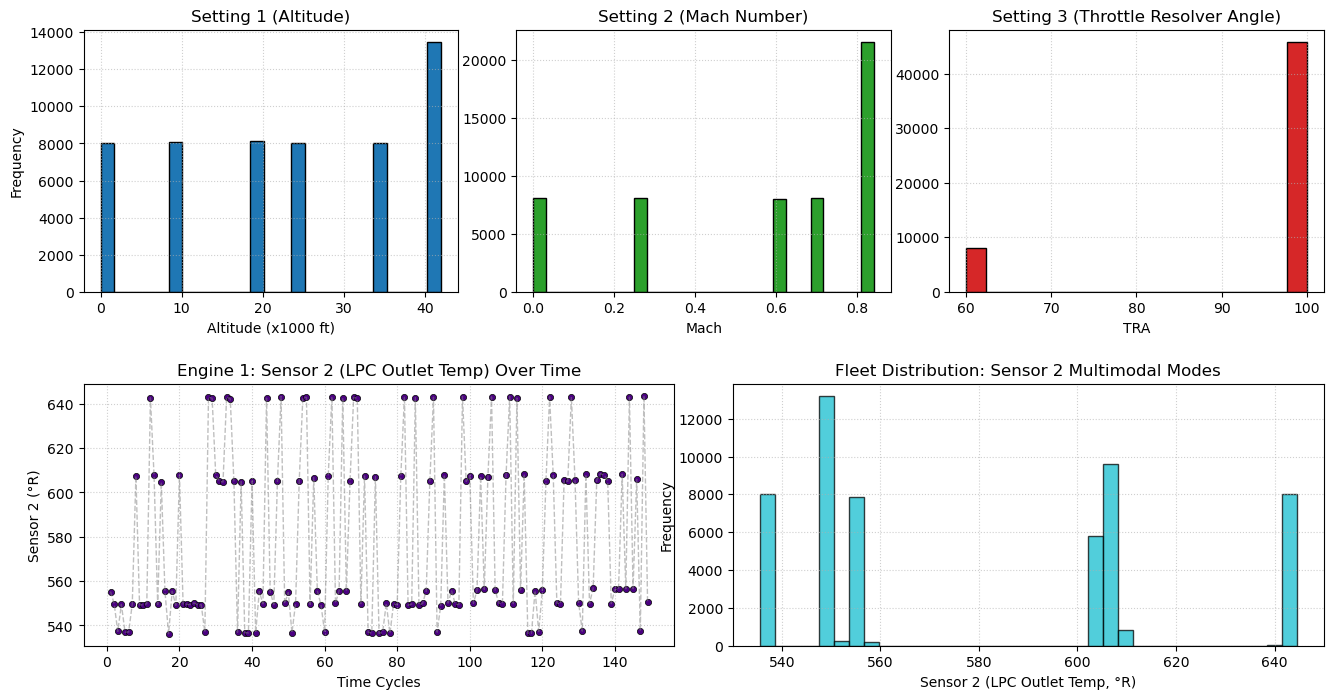

In [5]:
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 6, hspace=0.35, wspace=0.37)

# --- Row 1: Setting Histograms (3 subplots spanning 2 columns each) ---
ax1 = fig.add_subplot(gs[0, 0:2])
ax1.hist(df['setting_1'], bins='auto', color='tab:blue', edgecolor='black')
ax1.set_title("Setting 1 (Altitude)")
ax1.set_xlabel("Altitude (x1000 ft)")
ax1.set_ylabel("Frequency")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = fig.add_subplot(gs[0, 2:4])
ax2.hist(df['setting_2'], bins='auto', color='tab:green', edgecolor='black')
ax2.set_title("Setting 2 (Mach Number)")
ax2.set_xlabel("Mach")
ax2.grid(True, linestyle=":", alpha=0.6)

ax3 = fig.add_subplot(gs[0, 4:6])
ax3.hist(df['setting_3'], bins='auto', color='tab:red', edgecolor='black')
ax3.set_title("Setting 3 (Throttle Resolver Angle)")
ax3.set_xlabel("TRA")
ax3.grid(True, linestyle=":", alpha=0.6)

# --- Row 2: Sensor 2 Telemetry & Resulting Multimodal Histogram (3 columns each) ---
# Left: Engine 1 Time-Series
e1 = df[df['unit_nr'] == 1]
ax4 = fig.add_subplot(gs[1, 0:3])
ax4.plot(e1['time_cycles'], e1['sensor_2'], color='gray', linestyle='--', alpha=0.5, lw=1)
ax4.scatter(e1['time_cycles'], e1['sensor_2'], color='indigo', s=20, edgecolor='k', linewidth=0.5)
ax4.set_title("Engine 1: Sensor 2 (LPC Outlet Temp) Over Time")
ax4.set_xlabel("Time Cycles")
ax4.set_ylabel("Sensor 2 (°R)")
ax4.grid(True, linestyle=":", alpha=0.6)

# Right: Sensor 2 Histogram across the fleet showing the 6 modes
ax5 = fig.add_subplot(gs[1, 3:6])
ax5.hist(df['sensor_2'], bins='auto', color='tab:cyan', edgecolor='black', alpha=0.75)
ax5.set_title("Fleet Distribution: Sensor 2 Multimodal Modes")
ax5.set_xlabel("Sensor 2 (LPC Outlet Temp, °R)")
ax5.set_ylabel("Frequency")
ax5.grid(True, linestyle=":", alpha=0.6)

plt.show()

While the operational settings define six distinct flight regimes, individual sensor histograms (such as sensor_2) exhibit fewer separated modes. This occurs because distinct flight conditions can yield overlapping thermodynamic states at specific engine stations, and cumulative degradation drift broadens the distribution within each regime. This reinforces the need to identify operating regimes in the multivariate settings space rather than relying on univariate sensor thresholds.

In [6]:
print("Unique setting_3 values:", df['setting_3'].unique())
print(f"Total training engines: {df['unit_nr'].nunique()}")

Unique setting_3 values: [100.  60.]
Total training engines: 260


In [7]:

# Raw settings distributions
print("Unique setting_3 values:", df['setting_3'].unique())
print(f"Total training engines: {df['unit_nr'].nunique()}")

# Cluster the continuous flight settings into the 6 discrete regimes
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
df['op_cluster'] = kmeans.fit_predict(df[SETTING_COLS])

# Check cluster distribution across the dataset
print("\nOperating Regime Distribution:")
print(df['op_cluster'].value_counts(sort=False))

Unique setting_3 values: [100.  60.]
Total training engines: 260

Operating Regime Distribution:
op_cluster
5     8037
0    13458
2     8002
1     8122
3     8044
4     8096
Name: count, dtype: int64


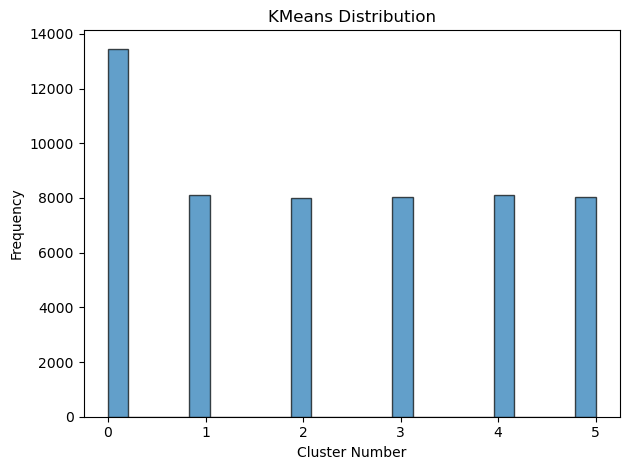

In [8]:
fig, ax = plt.subplots()
ax.hist(df['op_cluster'].values, bins = 'auto', edgecolor = 'black', alpha = 0.7)
ax.set_title('KMeans Distribution')
ax.set_xlabel('Cluster Number')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

### Six clusters can be see in the figure above

In [9]:
# Inspect the operational setpoints discovered by K-Means
# cycle_count is the total number of flight cycles (rows) belonging to a each cluster
regime_summary = (
    df.groupby('op_cluster')[SETTING_COLS]
    .mean()
    .round(2)
    .assign(cycle_count=df['op_cluster'].value_counts())
)
print(regime_summary)

            setting_1  setting_2  setting_3  cycle_count
op_cluster                                              
0                42.0       0.84      100.0        13458
1                20.0       0.70      100.0         8122
2                25.0       0.62       60.0         8002
3                 0.0       0.00      100.0         8044
4                10.0       0.25      100.0         8096
5                35.0       0.84      100.0         8037


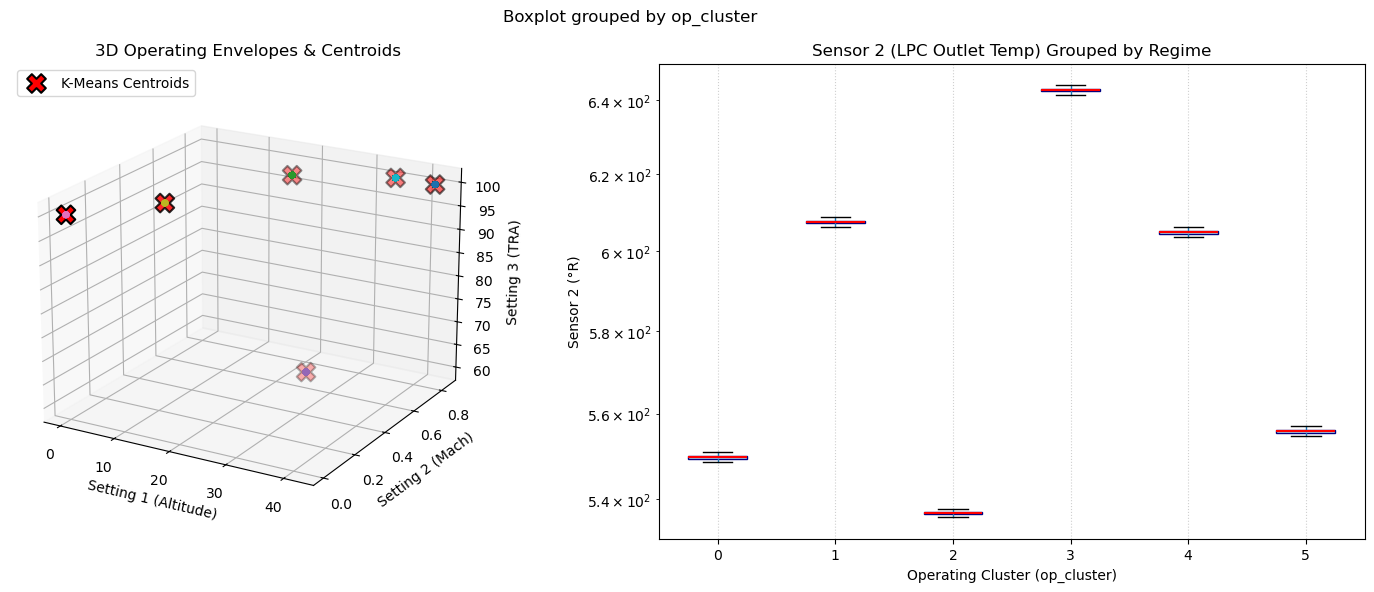

In [10]:
fig = plt.figure(figsize=(15, 6))

# --- Panel 1: 3D Operating Envelope with Centroids ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

scatter = ax1.scatter(
    df['setting_1'], 
    df['setting_2'], 
    df['setting_3'], 
    c=df['op_cluster'], 
    cmap='tab10', 
    alpha=0.15, 
    s=15
)

# Plot Centroids
centroids = kmeans.cluster_centers_
ax1.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    centroids[:, 2], 
    c='red', 
    marker='X', 
    s=180, 
    edgecolor='black', 
    linewidth=1.5, 
    label='K-Means Centroids'
)

ax1.set_title("3D Operating Envelopes & Centroids")
ax1.set_xlabel("Setting 1 (Altitude)")
ax1.set_ylabel("Setting 2 (Mach)")
ax1.set_zlabel("Setting 3 (TRA)")
ax1.view_init(elev=20, azim=-60)
ax1.legend(loc='upper left')

# --- Panel 2: Physical Verification on Sensor 2 ---
ax2 = fig.add_subplot(1, 2, 2)
df.boxplot(
    column='sensor_2', 
    by='op_cluster', # groupby
    ax=ax2, 
    grid=True, 
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor='lightblue', color='navy'),
    medianprops=dict(color='red', linewidth=1.5)
)

ax2.set_title("Sensor 2 (LPC Outlet Temp) Grouped by Regime")
#ax2.set_suptitle("")  # Clear default pandas title
ax2.set_xlabel("Operating Cluster (op_cluster)")
ax2.set_yscale('log')
ax2.set_ylabel("Sensor 2 (°R)")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

- Fitting $K$-Means across setting_1 (Altitude), setting_2 (Mach), and setting_3 (Throttle Resolver Angle) resolves the flight envelope into six distinct, non-overlapping geometric centroids. Five clusters capture high-power cruise and climb conditions ($\text{TRA} \approx 100^\circ$) across varying altitudes ($0\text{--}42\text{ kft}$), while the sixth isolates lower throttle demand ($\text{TRA} \approx 60^\circ$).
-  Grouping Sensor 2 (LPC Outlet Temperature) by assigned operating cluster collapses the fleet's raw multimodal distribution into six tight, distinct operating baselines. Within each cluster, the interquartile range (IQR) of the box-plot shrinks to a narrow band. It shows that macro-level sensor fluctuations across the dataset are driven by flight conditions rather than mechanical faults.

**Regime (cluster)-Specific Z-Score Normalization**
The next step is to remove operational variance by standardizing each sensor independently within each of the 6 operating regimes. For every sensor $s$ and operational cluster $k \in \{0, \dots, 5\}$, we compute the regime-specific mean $\mu_{k, s}$ and standard deviation $\sigma_{k, s}$ on the training set:
$$z_{i, s} = \frac{x_{i, s} - \mu_{k, s}}{\sigma_{k, s}}$$
This eliminates the $\approx 105^\circ\text{R}$ operational gaps, placing all operating conditions on a shared zero-mean, unit-variance baseline.Step 1: Compute Regime Statistics & Transform TelemetryTo prevent leakage, we extract the lookup statistics from the training set so the identical parameters can be applied downstream to test data:

### **Regime-Specific Z-Score Normalization**

Standardizing the entire fleet with a single global scaler fails because flight regime shifts (e.g., cruising at 40,000 ft vs. idling at sea level) mask gradual component wear. Instead, we standardize telemetry **within each flight regime independently**:

1. **Broadcasting Cluster Statistics (`transform`):** 
   Using `.transform('mean')` and `.transform('std')`, we calculate the baseline average and variation for each of the six flight regimes and align those values back to every corresponding flight cycle.
2. **Preventing Division-by-Zero:** 
   Sensors with zero variation within a given regime have their standard deviations replaced with `1.0` to avoid division-by-zero errors.
3. **Z-Score Transformation:** 
   Subtracting each regime's baseline mean and dividing by its standard deviation eliminates operational step-changes, centering every flight condition at $0.0$ and exposing the underlying mechanical degradation curve.

In [11]:
# Replaces each value directly with its group mean/std, keeping the original DataFrame shape
# Basically, it goes to each row, finds out the sensor value and which cluster it belongs, and then 
# inserts the cluster mean for that sensor.
means_mapped = df.groupby('op_cluster')[SENSOR_COLS].transform('mean')
stds_mapped = df.groupby('op_cluster')[SENSOR_COLS].transform('std').replace(0.0, 1.0)


In [12]:
print('Shape of means_mapped (transform method)', means_mapped.shape)
#print('Shape of cluster_means (groupby method)', cluster_means.shape)
print('Shape of df-----------------------------', df.shape)

Shape of means_mapped (transform method) (53759, 21)
Shape of df----------------------------- (53759, 27)


In [13]:
# Calculate the regime wise z-score normalized sensor values

norm_sensor_cols = [f"{col}_norm" for col in SENSOR_COLS]
# Calculate normalized features
df_norm = (df[SENSOR_COLS] - means_mapped) / stds_mapped
df_norm.columns = norm_sensor_cols

# Append normalized columns back to main DataFrame
df = pd.concat([df, df_norm], axis=1)

### **Note: All the subsequent training would be performed on the normalized sensor values**

### Before and After Normalization

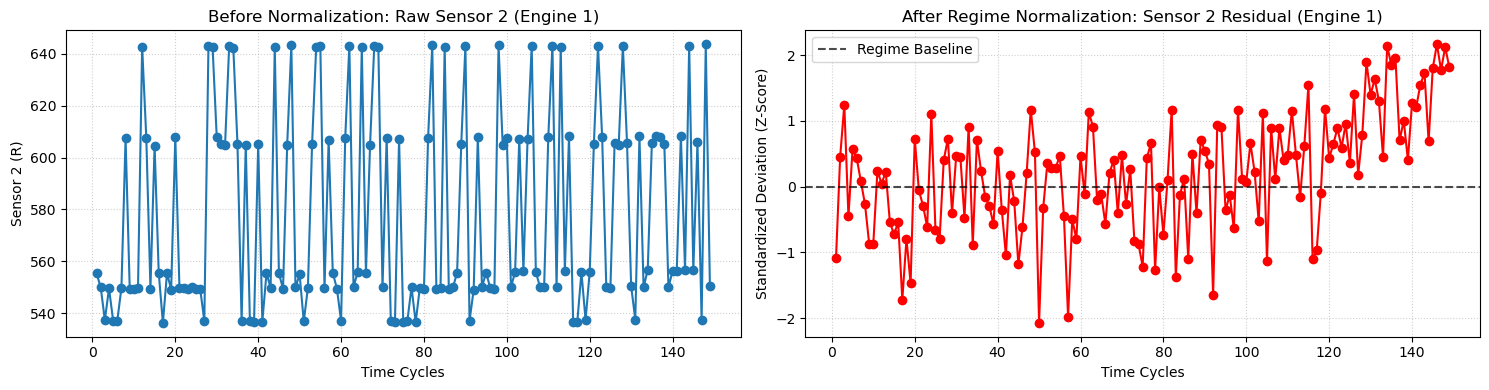

In [15]:
e1 = df[df['unit_nr'] == 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Raw Telemetry: Masked by Flight Regimes
axes[0].plot(e1['time_cycles'], e1['sensor_2'], 'o-')
axes[0].set_title("Before Normalization: Raw Sensor 2 (Engine 1)")
axes[0].set_xlabel("Time Cycles")
axes[0].set_ylabel("Sensor 2 (R)")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Normalized Telemetry: True Degradation Exposed
axes[1].plot(e1['time_cycles'], e1['sensor_2_norm'], 'ro-')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.7, label='Regime Baseline')
axes[1].set_title("After Regime Normalization: Sensor 2 Residual (Engine 1)")
axes[1].set_xlabel("Time Cycles")
axes[1].set_ylabel("Standardized Deviation (Z-Score)")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

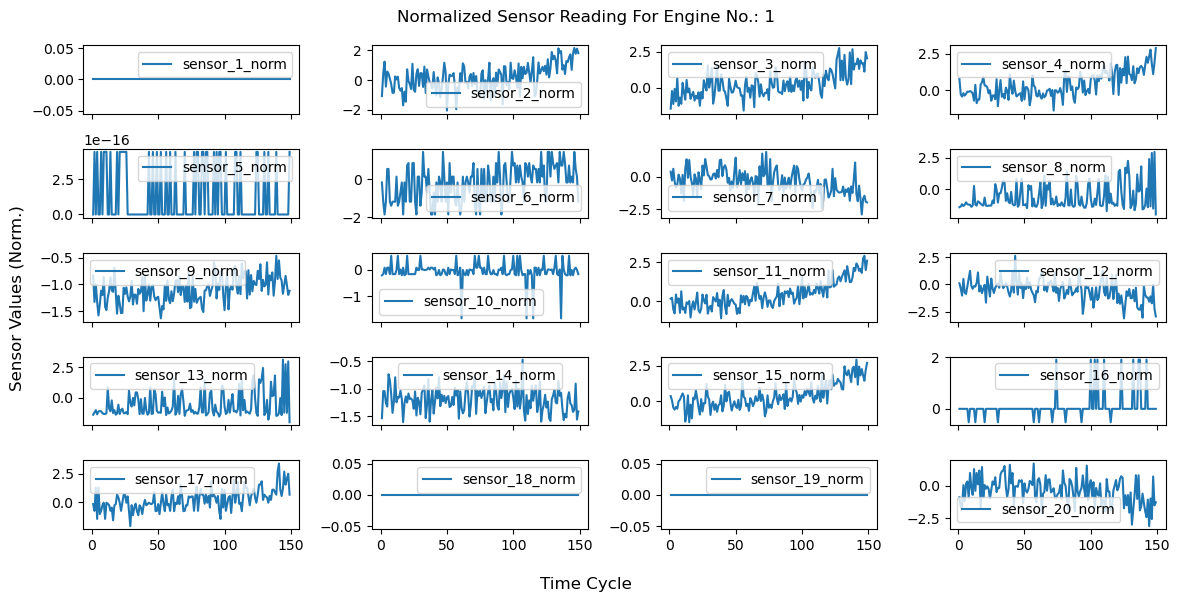

In [16]:
engine_no = 1
engine_df = df[df['unit_nr'] == engine_no]

fig, ax = plt.subplots(5, len(norm_sensor_cols)//5, sharex = True, figsize = (12,6))
for (x, s) in zip(ax.flatten(), norm_sensor_cols):
    x.plot(engine_df['time_cycles'], engine_df[s], label = s)
    #x.axvline(x=engine_df['max_cycle'].iloc[0], color = 'red', linestyle = '--', alpha = 0.6)
    x.legend()
fig.supxlabel('Time Cycle')
fig.supylabel('Sensor Values (Norm.)')
fig.suptitle(f'Normalized Sensor Reading For Engine No.: {engine_no}')
fig.tight_layout()

### **Remove flat sensors from consideration. Calculate the standard deviation in the normalized sensor values**

In [17]:
norm_sensor_std = df[norm_sensor_cols].std()
flat_norm_sensors = norm_sensor_std[norm_sensor_std < 1e-4].index.tolist()
print(flat_norm_sensors)
active_norm_sensors = [col for col in norm_sensor_cols if col not in flat_norm_sensors]
print(f"\nRetained {len(active_norm_sensors)} active sensor channels:")
print(active_norm_sensors)

['sensor_1_norm', 'sensor_5_norm', 'sensor_18_norm', 'sensor_19_norm']

Retained 17 active sensor channels:
['sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_6_norm', 'sensor_7_norm', 'sensor_8_norm', 'sensor_9_norm', 'sensor_10_norm', 'sensor_11_norm', 'sensor_12_norm', 'sensor_13_norm', 'sensor_14_norm', 'sensor_15_norm', 'sensor_16_norm', 'sensor_17_norm', 'sensor_20_norm', 'sensor_21_norm']


### Plot all the active sensors for an engine

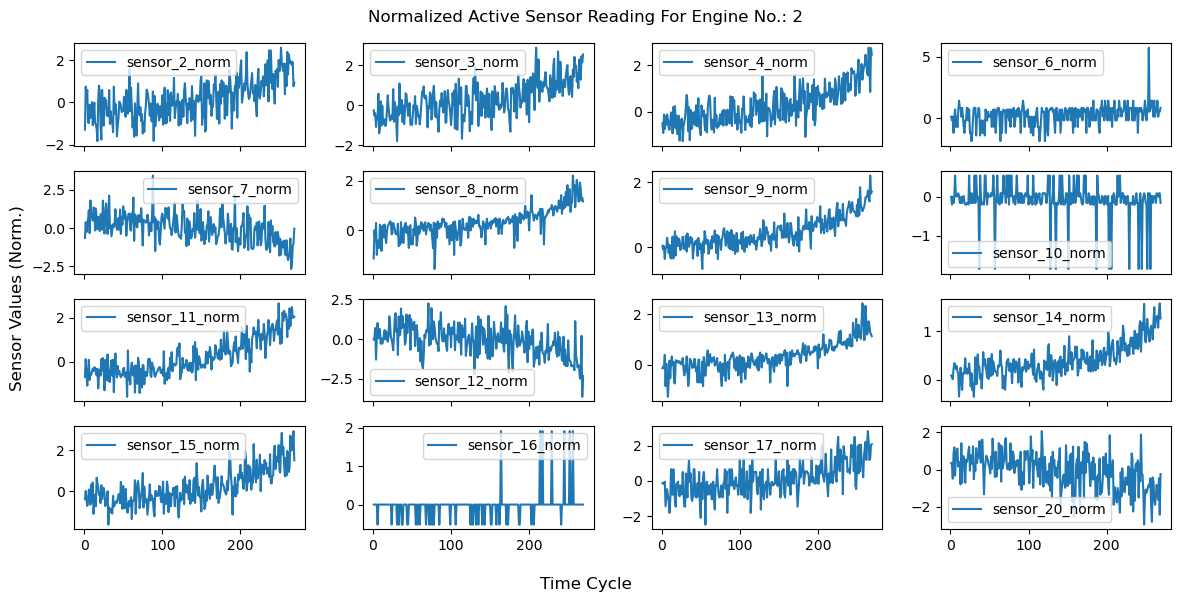

In [18]:
engine_no = 2
engine_df = df[df['unit_nr'] == engine_no]

#fig, ax = plt.subplots(5, len(active_norm_sensors)//5, sharex = True, figsize = (12,6))
fig, ax = plt.subplots(4,4, sharex = True, figsize = (12,6))

for (x, s) in zip(ax.flatten(), active_norm_sensors):
    x.plot(engine_df['time_cycles'], engine_df[s], label = s)
    #x.axvline(x=engine_df['max_cycle'].iloc[0], color = 'red', linestyle = '--', alpha = 0.6)
    x.legend()
fig.supxlabel('Time Cycle')
fig.supylabel('Sensor Values (Norm.)')
fig.suptitle(f'Normalized Active Sensor Reading For Engine No.: {engine_no}')
fig.tight_layout()

### Sensor 16 can be dropped as well

In [19]:
active_norm_sensors = [x for x in active_norm_sensors if x != 'sensor_16_norm']
print(active_norm_sensors)
print('Number of active sensors: ',len(active_norm_sensors))

['sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_6_norm', 'sensor_7_norm', 'sensor_8_norm', 'sensor_9_norm', 'sensor_10_norm', 'sensor_11_norm', 'sensor_12_norm', 'sensor_13_norm', 'sensor_14_norm', 'sensor_15_norm', 'sensor_17_norm', 'sensor_20_norm', 'sensor_21_norm']
Number of active sensors:  16


## **Section 2: Target Engineering (Piecewise RUL Formulation)**
In real-world, an engine does not start to get degraded at the first cycle of operation. New or newly serviced turbofans operate in a healthy, stable condition for dozens of cycles before showing any measurable wear. If a model is trained to predict a declining lifespan right from cycle 1, it will try to fit random sensor noise rather than genuine mechanical degradation. In order to minimize this effect, we cap the target lifespan at 125 cycles using a piecewise linear formulation:
$$RUL_{\text{clipped}} = \min(RUL_{\text{actual}}, 125)$$  
- Healthy Baseline ($RUL > 125$): The engine operates within normal tolerances, holding at a flat baseline of 125 cycles.
-  Active Wear ($RUL \le 125$): Once measurable degradation sets in, the remaining life drops linearly toward zero at failure. 



In [20]:
# Compute the remaining cycles
max_cycles = df.groupby('unit_nr')['time_cycles'].transform('max')
df['RUL_raw'] = max_cycles - df['time_cycles']


In [21]:
df.iloc[:,-5:].head(3)

,sensor_18_norm,sensor_19_norm,sensor_20_norm,sensor_21_norm,RUL_raw
0,0.0,0.0,-0.890351,-1.352264,148
1,0.0,0.0,-1.634704,-1.315545,147
2,0.0,0.0,-1.631271,1.720355,146


In [22]:
# Piecewise linear clipping at 125
RUL_CLIP_LIMIT = 125
df['RUL_clipped'] = df['RUL_raw'].clip(upper = RUL_CLIP_LIMIT)

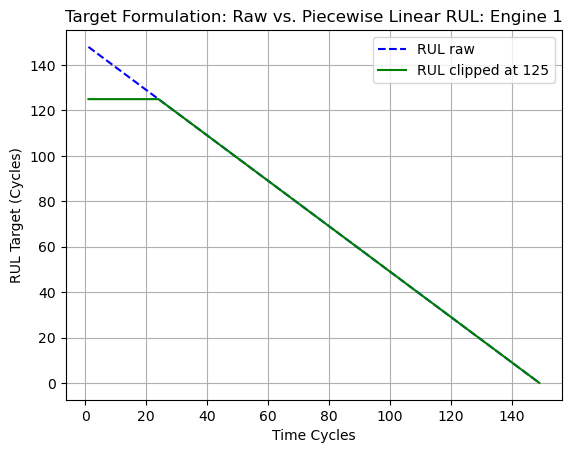

In [23]:
plt.figure()
plt.plot(df[df['unit_nr'] == 1]['time_cycles'], df[df['unit_nr'] == 1]['RUL_raw'], 'b--', label = 'RUL raw')
plt.plot(df[df['unit_nr'] == 1]['time_cycles'], df[df['unit_nr'] == 1]['RUL_clipped'], 'g-', label = f'RUL clipped at {RUL_CLIP_LIMIT}')
plt.xlabel("Time Cycles")
plt.ylabel("RUL Target (Cycles)")
plt.title("Target Formulation: Raw vs. Piecewise Linear RUL: Engine 1")
plt.legend()
plt.grid(True)
plt.show()

## **Section 3: Classical Machine Learning Baselines and Feature Engineering**
Models such as gradient-boosted decision trees (LightGBM, XGBoost) and regularized linear models (Ridge regression)  treat every row of data as an isolated snapshot. Because they do not naturally take into account time or sequence, looking at a single sensor reading won't reveal whether an engine is operating steadily or deteriorating quickly.  To give such tabular models a clear sense of trend and degradation history, we engineer temporal features directly from the raw telemetry:  
- Rolling Statistics: Calculating rolling averages and standard deviations across short- and long-term cycle windows captures gradual baseline drift while smoothing out flight-to-flight noise.

Expanding our 16 active sensors into these engineered features  helps these models to look past normal sensor jitter and focus on genuine mechanical wear.

In [24]:
WINDOW_SIZES = [5,10,15]
feature_cols = ['unit_nr', 'time_cycles', 'op_cluster'] + active_norm_sensors
df_features = df[feature_cols].copy()
# groupby unit_nr or engine
grouped = df_features.groupby('unit_nr')[active_norm_sensors]

rolling_dfs = []

for w in WINDOW_SIZES:
    # rolling mean
    rolling_mean = grouped.rolling(window = w, min_periods = 1).mean().reset_index(level = 0, drop = True)
    rolling_mean.columns = [f"{col}_mean_w{w}" for col in active_norm_sensors]
    # rolling standard deviation
    rolling_std = grouped.rolling(window = w, min_periods = 1).std().fillna(0).reset_index(level = 0, drop = True)
    rolling_std.columns = [f"{col}_std_w{w}" for col in active_norm_sensors]
    rolling_dfs.extend([rolling_mean, rolling_std])

In [25]:
rolling_dfs[0].head(2)

,sensor_2_norm_mean_w5,sensor_3_norm_mean_w5,sensor_4_norm_mean_w5,sensor_6_norm_mean_w5,sensor_7_norm_mean_w5,sensor_8_norm_mean_w5,sensor_9_norm_mean_w5,sensor_10_norm_mean_w5,sensor_11_norm_mean_w5,sensor_12_norm_mean_w5,sensor_13_norm_mean_w5,sensor_14_norm_mean_w5,sensor_15_norm_mean_w5,sensor_17_norm_mean_w5,sensor_20_norm_mean_w5,sensor_21_norm_mean_w5
0,-1.090273,-1.44299,0.769983,-0.174680,0.412668,-1.400728,-0.835436,-0.201625,0.163626,0.097684,-1.395729,-1.531522,0.361665,-0.167394,-0.890351,-1.352264
1,-0.319748,-0.83182,0.252578,-0.679695,0.069264,-1.370217,-1.081903,-0.179960,0.189053,-0.141230,-1.304501,-1.285789,0.212087,-0.462232,-1.262528,-1.333904


In [26]:
df_features = pd.concat([df_features] + rolling_dfs,  axis = 1)
df_features.head()

,unit_nr,time_cycles,op_cluster,sensor_2_norm,sensor_3_norm,sensor_4_norm,sensor_6_norm,sensor_7_norm,sensor_8_norm,sensor_9_norm,...,sensor_9_norm_std_w15,sensor_10_norm_std_w15,sensor_11_norm_std_w15,sensor_12_norm_std_w15,sensor_13_norm_std_w15,sensor_14_norm_std_w15,sensor_15_norm_std_w15,sensor_17_norm_std_w15,sensor_20_norm_std_w15,sensor_21_norm_std_w15
0,1,1,5,-1.090273,-1.442990,0.769983,-0.174680,0.412668,-1.400728,-0.835436,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,2,0,0.450777,-0.220650,-0.264827,-1.184711,-0.274140,-1.339706,-1.328371,...,0.348558,0.030639,0.035959,0.337875,0.129015,0.347519,0.211536,0.416964,0.526337,0.025964
2,1,3,2,1.242381,-1.122003,-0.421643,-1.856112,0.634410,-1.165778,-0.998485,...,0.251129,0.156832,0.418353,0.563089,0.185643,0.283108,0.415695,1.046944,0.428764,1.763473
3,1,4,0,-0.450228,-0.076868,-0.186263,-1.184711,-0.388003,-1.306342,-1.328371,...,0.246679,0.132491,0.503030,0.656081,0.170645,0.232867,0.446876,1.165563,0.791000,1.800233
4,1,5,2,0.572229,-0.942097,-0.351147,0.535612,-0.839675,-1.203904,-1.579340,...,0.295547,0.144488,0.526651,0.621110,0.156884,0.206834,0.403031,1.226060,0.688497,1.588054


In [27]:
# include RUL columns
df_features['RUL_clipped'] = df['RUL_clipped']
df_features['RUL_raw'] = df['RUL_raw']


In [28]:
print('Feature df shape:', df_features.shape)

Feature df shape: (53759, 117)


### We need to keep only the sensor related information for  training

In [29]:
# We keep only the sensor related columns
ignore_cols = ['unit_nr', 'time_cycles', 'RUL_raw', 'RUL_clipped']
MODEL_FEATURES = [col for col in df_features.columns if col not in ignore_cols]

In [30]:
print('No of features for model training: ',len(MODEL_FEATURES))

No of features for model training:  113


# **Load the test data and prepare it**

### Leak-Free Regime Normalization 
- To ensure realistic generalization and prevent data leakage, all regime baseline statistics ($\mu_r$ and $\sigma_r$) are derived strictly from the training data. 
- In a live deployment, incoming flight telemetry arrives incrementally for unseen engines. Calculating batch statistics directly on the test set would expose the pipeline to information from the test distribution.
- Test cycles are assigned to their nearest K-Means cluster and normalized using the training set's lookup parameters:$$z_{\text{test}} = \frac{x_{\text{test}} - \mu_{\text{train}, r}}{\sigma_{\text{train}, r}}$$This projects unseen engine telemetry onto the established baseline.

In [31]:
test_raw = pd.read_csv(DATA_DIR/'test_FD002.txt', sep = r'\s+', header = None, names = COLUMN_NAMES)
rul_true = pd.read_csv(DATA_DIR/'RUL_FD002.txt', sep = r'\s+', header = None, names = ['true_RUL'])

In [32]:
#clip the true RUL values
y_test_true = rul_true['true_RUL'].clip(upper = 125).values


In [33]:
# K-means on test data
test_raw['op_cluster'] = kmeans.predict(test_raw[SETTING_COLS])


In [34]:
# Now we have to find the regime wise normalization for the training data that will be mapped to the test data.
# Compute and store regime baseline statistics from TRAIN data
cluster_means = df.groupby('op_cluster')[SENSOR_COLS].mean()
cluster_stds = df.groupby('op_cluster')[SENSOR_COLS].std().replace(0.0, 1.0)

In [35]:
# Now leak free regime normalization of the test data using the stats from the training data that we calculated.
test_means = test_raw['op_cluster'].map(cluster_means.to_dict('index')).apply(pd.Series)
test_stds = test_raw['op_cluster'].map(cluster_stds.to_dict('index')).apply(pd.Series)


In [36]:
print(f"Test Raw df shape: {test_raw.shape}")
print(f"Test means df shape: {test_means.shape}")

Test Raw df shape: (33991, 27)
Test means df shape: (33991, 21)


In [37]:
test_norm = (test_raw[SENSOR_COLS] - test_means)/test_stds
test_norm.columns = norm_sensor_cols
test_features = pd.concat([test_raw, test_norm], axis = 1)
print(f"Test Raw df shape: {test_raw.shape}")
print(f"Test Features df shape: {test_features.shape}")


Test Raw df shape: (33991, 27)
Test Features df shape: (33991, 48)


In [38]:
# Rolling stats for test data
test_grouped = test_features.groupby('unit_nr')[active_norm_sensors]
test_rolling_dfs = []
for w in WINDOW_SIZES:
    r_mean = test_grouped.rolling(window = w, min_periods = 1).mean().reset_index(level = 0, drop = True)
    r_mean.columns = [f"{col}_mean_w{w}" for col in active_norm_sensors]
    r_std = test_grouped.rolling(window = w, min_periods = 1).std().fillna(0.0).reset_index(level = 0, drop = True)
    r_std.columns = [f"{col}_std_w{w}" for col in active_norm_sensors]
    test_rolling_dfs.extend([r_mean, r_std])


In [39]:
test_features = pd.concat([test_features] + test_rolling_dfs, axis = 1)
print(f"test_features shape: {test_features.shape}")

test_features shape: (33991, 144)


In [40]:
# Find the last entered cycle for each engine
test_last_cycles = test_features.groupby('unit_nr').last().reset_index()
print('Test Last Cycles Shape', test_last_cycles.shape)

Test Last Cycles Shape (259, 144)


In [42]:
df_features.shape

(53759, 117)

In [43]:
# Verify exact column match and ordering between train and test
assert list(df_features[MODEL_FEATURES].columns) == list(test_last_cycles[MODEL_FEATURES].columns), \
    "Mismatch between train and test feature columns!"

# **Split data into training and test**

### **Training set**

In [44]:
X = df_features[MODEL_FEATURES]
y = df_features['RUL_clipped']
groups = df_features['unit_nr']

### **Test Set**

In [45]:
X_test = test_last_cycles[MODEL_FEATURES]

In [46]:
print(f"X train shape: {X.shape}")
print(f"y train shape: {y.shape}")
print(f"X_test shape:  {X_test.shape} ")
print(f"y_test shape:  {y_test_true.shape}")
print(f"Model features: {len(MODEL_FEATURES)}")

X train shape: (53759, 113)
y train shape: (53759,)
X_test shape:  (259, 113) 
y_test shape:  (259,)
Model features: 113


# **The Asymmetric NASA Scoring Function**
Standard regression metrics like RMSE and MAE treat errors symmetrically, penalizing an over-prediction and an under-prediction of 10 cycles identically. In aviation maintenance and reliability engineering, however, the real-world operational consequences are vastly different:  
- Early Prediction ($\hat{y} < y$, $d_i < 0$): The model predicts failure sooner than it actually occurs. This prompts early inspection or proactive component replacement. While it carries a minor capital and logistics cost, the aircraft remains safe.
- Late Prediction ($\hat{y} > y$, $d_i > 0$): The model overestimates the engine's remaining lifespan, clearing a degrading asset for commercial flight. This introduces severe safety risks, including in-flight engine shutdowns (IFSD) and catastrophic structural failure.

To mathematically reflect this trade-off, the NASA C-MAPSS benchmark implements an asymmetric exponential scoring function:  $$S = \sum_{i=1}^{N} s_i, \quad s_i = \begin{cases} e^{-\frac{d_i}{13}} - 1 & \text{for } d_i < 0 \quad (\text{Early / Conservative}) \\ e^{\frac{d_i}{10}} - 1 & \text{for } d_i \ge 0 \quad (\text{Late / Dangerous}) \end{cases}$$  
where $d_i = \hat{y}_i - y_i$ represents the prediction error in operational cycles.  Because the divisor in the exponent is smaller for late estimates ($10$ vs. $13$), late-cycle overestimates trigger an aggressive exponential penalty. An algorithm that achieves a strong RMSE can still fail operationally if it consistently overestimates engine life, making this metric critical for validating flight-readiness models. 

In [47]:
def compute_nasa_score(y_true, y_pred):
    """
    NASA C-MAPSS scoring function.
    Penalizes late predictions (y_pred > y_true) significantly harder than early predictions.
    """
    d = y_pred - y_true
    score = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return np.sum(score)

### **Training classical ML models**

In [48]:
warnings.filterwarnings("ignore", category=UserWarning)

# Pipeline definitions
models_to_benchmark = {
    'RidgeRegression': make_pipeline(
        StandardScaler(),
        RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0, 500.0])
    ),
    'RandomForest': make_pipeline(
        StandardScaler(),
        RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
    ),
    'XGBoost': make_pipeline(
        StandardScaler(),
        XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=5, random_state=42, verbosity=0)
    ),
    'LightGBM': make_pipeline(
        StandardScaler(),
        lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbosity=-1)
    )
}

In [49]:


# 5-Fold Grouped Cross-Validation
gkf = GroupKFold(n_splits=5)
benchmark_results = []
preds_from_models = {}
all_trained_models = {}
total_steps = len(models_to_benchmark) * gkf.n_splits
pbar = tqdm(total=total_steps, desc="Benchmarking Models", unit="fold")

for name, model_template in models_to_benchmark.items():
    t0 = time.time()
    oof_preds = np.zeros(len(X))
    fold_models = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), 1):
        pbar.set_postfix({"Model": name, "Fold": f"{fold}/5"})
        
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
        
        model = clone(model_template)
        model.fit(X_train, y_train)
        
        # Clip out-of-fold predictions to valid bounds
        raw_val_pred = model.predict(X_val)
        oof_preds[val_idx] = np.clip(raw_val_pred, 0, 125)
        fold_models.append(model)
        pbar.update(1)
        
    all_trained_models[name] = fold_models
    # Validation metrics
    cv_rmse = np.sqrt(mean_squared_error(y, oof_preds))
    cv_mae = mean_absolute_error(y, oof_preds)
    
    # Test inference (5-fold ensemble average)
    raw_test_pred = np.mean([m.predict(X_test) for m in fold_models], axis=0)
    test_pred = np.clip(raw_test_pred, 0, 125)
    preds_from_models[f"pred_{name.lower().replace(' ', '_')}"] = test_pred
    
    # Test evaluation
    test_rmse = np.sqrt(mean_squared_error(y_test_true, test_pred))
    test_mae = mean_absolute_error(y_test_true, test_pred)
    test_nasa = compute_nasa_score(y_test_true, test_pred)
    elapsed = time.time() - t0
    
    print(f"✓ {name:<16} | CV RMSE: {cv_rmse:.2f} | Test RMSE: {test_rmse:.2f} | Test NASA: {test_nasa:.1f} | Time: {elapsed:.1f}s")
    
    benchmark_results.append({
        "Model": name,
        "cv_rmse": round(cv_rmse, 2),
        "cv_mae": round(cv_mae, 2),
        "test_rmse": round(test_rmse, 2),
        "test_mae": round(test_mae, 2),
        "test_nasa": round(test_nasa, 1)
    })

pbar.close()

# Display summary leaderboard
df_leaderboard = pd.DataFrame(benchmark_results).sort_values("test_rmse")
display(df_leaderboard)

Benchmarking Models:  25%|██▌       | 5/20 [00:02<00:06,  2.23fold/s, Model=RandomForest, Fold=1/5]   

✓ RidgeRegression  | CV RMSE: 19.30 | Test RMSE: 18.42 | Test NASA: 1681.0 | Time: 2.3s


Benchmarking Models:  50%|█████     | 10/20 [03:37<06:00, 36.05s/fold, Model=XGBoost, Fold=1/5]     

✓ RandomForest     | CV RMSE: 19.06 | Test RMSE: 16.00 | Test NASA: 1553.4 | Time: 215.4s


Benchmarking Models:  75%|███████▌  | 15/20 [03:51<00:40,  8.19s/fold, Model=LightGBM, Fold=1/5]

✓ XGBoost          | CV RMSE: 18.55 | Test RMSE: 16.00 | Test NASA: 1544.9 | Time: 13.5s


Benchmarking Models: 100%|██████████| 20/20 [04:01<00:00, 12.10s/fold, Model=LightGBM, Fold=5/5]

✓ LightGBM         | CV RMSE: 18.62 | Test RMSE: 15.99 | Test NASA: 1520.6 | Time: 10.8s


,Model,cv_rmse,cv_mae,test_rmse,test_mae,test_nasa
3,LightGBM,18.62,13.39,15.99,11.79,1520.6
1,RandomForest,19.06,13.75,16.00,12.06,1553.4
2,XGBoost,18.55,13.36,16.00,11.82,1544.9
0,RidgeRegression,19.30,14.74,18.42,14.71,1681.0


In [50]:
lgb_importances_fold_wise = []
for fold in all_trained_models['LightGBM']:
    imp = fold.named_steps['lgbmregressor'].feature_importances_
    lgb_importances_fold_wise.append(imp)
lgb_importances = np.mean(lgb_importances_fold_wise, axis = 0)

### See which features are the most important in LightGBM

In [51]:
# Structure into a DataFrame
df_importance = pd.DataFrame({
    'Feature': MODEL_FEATURES,
    'Importance': lgb_importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

# Display top 15 table
#display(df_importance.head(15))

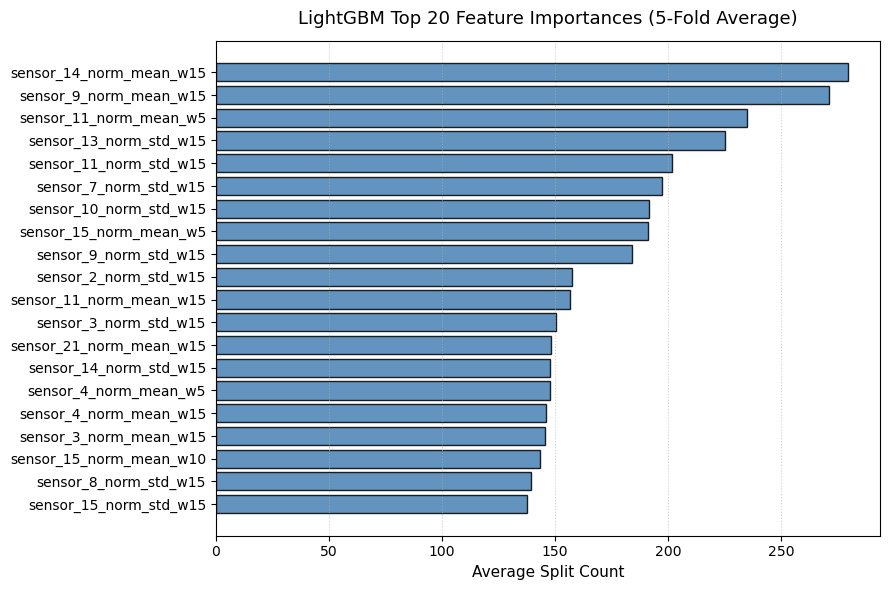

In [52]:
# Plot Top 20 Features
TOP_N = 20
plot_df = df_importance.head(TOP_N).sort_values('Importance', ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(plot_df['Feature'], plot_df['Importance'], color='steelblue', edgecolor='black', alpha=0.85)
plt.title(f'LightGBM Top {TOP_N} Feature Importances (5-Fold Average)', fontsize=13, pad=12)
plt.xlabel('Average Split Count', fontsize=11)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [53]:
# Assemble results DataFrame aligned by test unit
results_df_models = pd.DataFrame({
    'unit_nr': test_raw['unit_nr'].unique(),
    'true_RUL': y_test_true,
    'pred_ridge': preds_from_models['pred_ridgeregression'],
    'pred_rf': preds_from_models['pred_randomforest'],
    'pred_xgb': preds_from_models['pred_xgboost'],
    'pred_lgb': preds_from_models['pred_lightgbm']
}).sort_values(by='true_RUL').reset_index(drop=True)

# Quick view of extreme engines (lowest and highest RUL)
display(results_df_models.head(5))

,unit_nr,true_RUL,pred_ridge,pred_rf,pred_xgb,pred_lgb
0,44,6,18.040224,9.434458,11.174718,9.993766
1,177,6,8.439986,6.256261,5.645666,4.925014
2,211,6,14.545625,9.032291,6.684832,5.518297
3,7,6,21.613304,7.176246,4.917709,5.686312
4,11,6,6.827253,14.238771,13.660048,13.189051


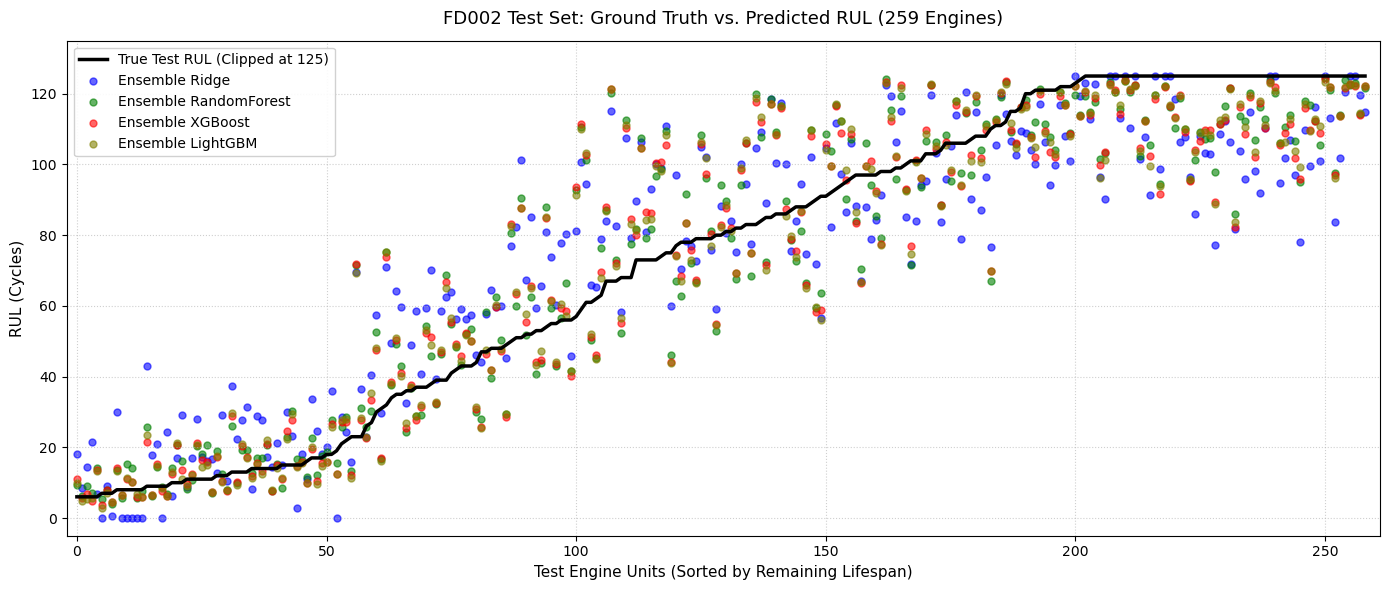

In [54]:
# Plot True RUL vs Model Predictions (Sorted)
plt.figure(figsize=(14, 6))

# Ground truth line
plt.plot(results_df_models['true_RUL'], label='True Test RUL (Clipped at 125)', color='black', lw=2.5, zorder=5)
# Model predictions
plt.scatter(results_df_models.index, results_df_models['pred_ridge'], 
            alpha=0.6, s=25, label='Ensemble Ridge', color='blue')
plt.scatter(results_df_models.index, results_df_models['pred_rf'], 
            alpha=0.6, s=25, label='Ensemble RandomForest', color='green')
plt.scatter(results_df_models.index, results_df_models['pred_xgb'], 
            alpha=0.6, s=25, label='Ensemble XGBoost', color='red')
plt.scatter(results_df_models.index, results_df_models['pred_lgb'], 
            alpha=0.6, s=25, label='Ensemble LightGBM', color='olive')

plt.xlabel('Test Engine Units (Sorted by Remaining Lifespan)', fontsize=11)
plt.ylabel('RUL (Cycles)', fontsize=11)
plt.title('FD002 Test Set: Ground Truth vs. Predicted RUL (259 Engines)', fontsize=13, pad=12)
plt.legend(loc='upper left', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(-2, len(results_df_models) + 2)
plt.ylim(-5, 135)
plt.tight_layout()
plt.show()

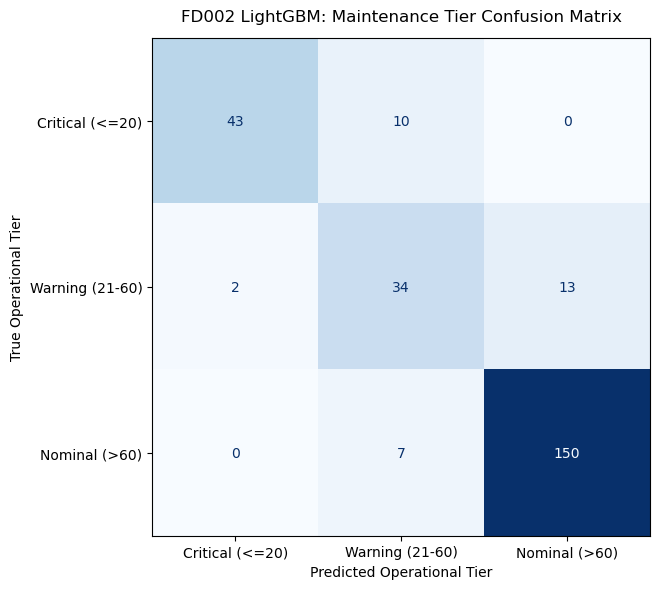

                 precision    recall  f1-score   support

Critical (<=20)       0.96      0.81      0.88        53
Warning (21-60)       0.67      0.69      0.68        49
  Nominal (>60)       0.92      0.96      0.94       157

       accuracy                           0.88       259
      macro avg       0.85      0.82      0.83       259
   weighted avg       0.88      0.88      0.88       259



In [55]:
# Define operational maintenance bins and labels
bins = [-np.inf, 20, 60, np.inf]
labels = ['Critical (<=20)', 'Warning (21-60)', 'Nominal (>60)']

# Discretize ground truth and LightGBM predictions
y_test_cat = pd.cut(results_df_models['true_RUL'], bins=bins, labels=labels)
pred_lgb_cat = pd.cut(results_df_models['pred_lgb'], bins=bins, labels=labels)

# Compute Confusion Matrix
cm = confusion_matrix(y_test_cat, pred_lgb_cat, labels=labels)

# Plot Heatmap
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, values_format='d', colorbar=False)

plt.title('FD002 LightGBM: Maintenance Tier Confusion Matrix', fontsize=12, pad=12)
plt.xlabel('Predicted Operational Tier', fontsize=10)
plt.ylabel('True Operational Tier', fontsize=10)
plt.grid(False)
plt.tight_layout()
plt.show()

# Display precision, recall, and F1-scores
print(classification_report(y_test_cat, pred_lgb_cat, labels=labels))

### LightGBM emerged as the top classical baseline
- Reliable Safety Guardrails: Zero catastrophic misses—no critical engine ($\le 20$ cycles) was misclassified as nominal ($>60$ cycles).
- High Critical Detection: Caught 43 of 53 engines requiring immediate depot intervention.
- Despite these results, tree models rely on hand-engineered rolling windows ($w = 5, 10, 15, 30$) that flatten time into static summary statistics. This introduces clear operational bottlenecks, for instance 10 critical engines were under-called, delaying maintenance scheduling into the Warning tier. To track continuous wear dynamics across flight regimes without manual windowing, we now transition from 2D tabular features to 3D sequential tensors $(N \times 30 \times 16)$ using Stacked LSTMs and 1D-CNNs.

##  **Section 4: Deep Learning (Stacked LSTM & 1D-CNN)**

In [56]:
SEQUENCE_LENGTH = 30
ACTIVE_SENSORS = active_norm_sensors  # 16 active normalized channels

# 1. Scale sensor features to [0, 1] using training distribution only
scaler = MinMaxScaler()

df_train_scaled = df_features[["unit_nr", "time_cycles", "RUL_clipped"] + ACTIVE_SENSORS].copy()
df_train_scaled[ACTIVE_SENSORS] = scaler.fit_transform(df_train_scaled[ACTIVE_SENSORS])

test_scaled = test_features[["unit_nr", "time_cycles"] + ACTIVE_SENSORS].copy()
test_scaled[ACTIVE_SENSORS] = scaler.transform(test_scaled[ACTIVE_SENSORS])


# 2. Sliding window generator functions (Exact FD001 Structure)
def gen_train_sequences(df, seq_length, feature_cols, target_col):
    """Extracts sliding window 3D tensors and corresponding RUL targets."""
    sequences = []
    labels = []

    for unit in df["unit_nr"].unique():
        unit_data = df[df["unit_nr"] == unit]
        feature_mat = unit_data[feature_cols].values
        target_vec = unit_data[target_col].values

        num_windows = len(unit_data) - seq_length + 1
        for i in range(num_windows):
            sequences.append(feature_mat[i : i + seq_length])
            labels.append(target_vec[i + seq_length - 1])

    return np.array(sequences, dtype=np.float32), np.array(labels, dtype=np.float32)


def gen_test_sequences(df, seq_length, feature_cols):
    """Extracts only the last sequence of length W for each test engine."""
    sequences = []

    for unit in df["unit_nr"].unique():
        unit_data = df[df["unit_nr"] == unit]
        feature_mat = unit_data[feature_cols].values

        # If engine history is shorter than window, pad with initial cycle values
        if len(feature_mat) < seq_length:
            padding = np.repeat(feature_mat[0:1], seq_length - len(feature_mat), axis=0)
            seq = np.vstack([padding, feature_mat])
        else:
            seq = feature_mat[-seq_length:]

        sequences.append(seq)

    return np.array(sequences, dtype=np.float32)




In [57]:
# Generate 3D test array
X_test_seq = gen_test_sequences(test_scaled, SEQUENCE_LENGTH, ACTIVE_SENSORS)
print(f"X_test 3D Shape: {X_test_seq.shape}")  # Expected: (259, 30, 16)

X_test 3D Shape: (259, 30, 16)


In [58]:
len(X_test_seq[0][0])

16

### Create the models

In [59]:
def build_lstm_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(units=64, return_sequences=True),
        Dropout(0.2),
        LSTM(units=32, return_sequences=False),
        Dropout(0.2),
        Dense(units=32, activation="relu"),
        Dense(units=1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model

def build_cnn_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=64, kernel_size=3, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=32, kernel_size=3, activation="relu", padding="same"),
        GlobalAveragePooling1D(),
        Dense(units=32, activation="relu"),
        Dropout(0.2),
        Dense(units=1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model

In [60]:
print(f"No of model features with rolling stats                       : {len(MODEL_FEATURES)}")
print(f"No of features in  active_norm_sensors (only sensor reading)  : {len(active_norm_sensors)}")
print(f"No of features in  ACTIVE_SENSORS (only sensor reading)       : {len(ACTIVE_SENSORS)}")

No of model features with rolling stats                       : 113
No of features in  active_norm_sensors (only sensor reading)  : 16
No of features in  ACTIVE_SENSORS (only sensor reading)       : 16


## **Section 5: Engine Level Cross Validation**

In [61]:
unique_units = df_features['unit_nr'].unique()
gkf = GroupKFold(n_splits=5)

# Tracking containers
lstm_models, lstm_val_rmse, lstm_test_preds, lstm_histories = [], [], [], []
cnn_models, cnn_val_rmse, cnn_test_preds, cnn_histories = [], [], [], []

FEATURE_COLS = ACTIVE_SENSORS # WHICH IS active_norm_sensors (total no 16)
print("Starting 5-Fold GroupKFold Cross-Validation (LSTM vs. 1D-CNN)...")

for fold, (train_unit_idx, val_unit_idx) in enumerate(gkf.split(unique_units, groups=unique_units)):
    print(f"\n--- Fold {fold + 1} / 5 ---")
    tf.keras.backend.clear_session()
    
    # Engine IDs for this fold
    train_units = unique_units[train_unit_idx]
    val_units = unique_units[val_unit_idx]
    
    df_fold_train = df_train_scaled[df_train_scaled['unit_nr'].isin(train_units)].copy()
    df_fold_val   = df_train_scaled[df_train_scaled['unit_nr'].isin(val_units)].copy()
       
    # Generate 3D sequences or arrays per fold from scaled inputs
    X_train_f, y_train_f = gen_train_sequences(df_fold_train, SEQUENCE_LENGTH, ACTIVE_SENSORS, "RUL_clipped")
    X_val_f, y_val_f     = gen_train_sequences(df_fold_val, SEQUENCE_LENGTH, ACTIVE_SENSORS, "RUL_clipped")
        
    callbacks = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)]
    
    # 1. Train Stacked LSTM
    model_lstm = build_lstm_model((SEQUENCE_LENGTH, len(ACTIVE_SENSORS)))
    history_lstm = model_lstm.fit(
        X_train_f, y_train_f,
        validation_data=(X_val_f, y_val_f),
        epochs=80,
        batch_size=128,
        callbacks=callbacks,
        verbose=0
    )
    lstm_histories.append(history_lstm)
    
    val_preds_lstm = model_lstm.predict(X_val_f, verbose=0).flatten()
    rmse_lstm = np.sqrt(mean_squared_error(y_val_f, np.clip(val_preds_lstm, 0, 125)))
    lstm_val_rmse.append(rmse_lstm)
    
    lstm_test_preds.append(model_lstm.predict(X_test_seq, verbose=0).flatten())
    lstm_models.append(model_lstm)
    
    # 2. Train 1D-CNN
    model_cnn = build_cnn_model((SEQUENCE_LENGTH, len(ACTIVE_SENSORS)))
    history_cnn = model_cnn.fit(
        X_train_f, y_train_f,
        validation_data=(X_val_f, y_val_f),
        epochs=80,
        batch_size=128,
        callbacks=callbacks,
        verbose=0
    )
    cnn_histories.append(history_cnn)
    
    val_preds_cnn = model_cnn.predict(X_val_f, verbose=0).flatten()
    rmse_cnn = np.sqrt(mean_squared_error(y_val_f, np.clip(val_preds_cnn, 0, 125)))
    cnn_val_rmse.append(rmse_cnn)
    
    cnn_test_preds.append(model_cnn.predict(X_test_seq, verbose=0).flatten())
    cnn_models.append(model_cnn)
    
    print(f"Fold {fold + 1} | LSTM Val RMSE: {rmse_lstm:.2f} | CNN Val RMSE: {rmse_cnn:.2f}")

# Cross-Validation Summary
print(f"\nMean CV RMSE (LSTM): {np.mean(lstm_val_rmse):.2f} ± {np.std(lstm_val_rmse):.2f}")
print(f"Mean CV RMSE (CNN):  {np.mean(cnn_val_rmse):.2f} ± {np.std(cnn_val_rmse):.2f}")

Starting 5-Fold GroupKFold Cross-Validation (LSTM vs. 1D-CNN)...

--- Fold 1 / 5 ---

Fold 1 | LSTM Val RMSE: 14.82 | CNN Val RMSE: 16.41

--- Fold 2 / 5 ---
Fold 2 | LSTM Val RMSE: 16.18 | CNN Val RMSE: 18.12

--- Fold 3 / 5 ---
Fold 3 | LSTM Val RMSE: 15.35 | CNN Val RMSE: 17.17

--- Fold 4 / 5 ---
Fold 4 | LSTM Val RMSE: 15.29 | CNN Val RMSE: 17.25

--- Fold 5 / 5 ---
Fold 5 | LSTM Val RMSE: 14.47 | CNN Val RMSE: 15.22

Mean CV RMSE (LSTM): 15.22 ± 0.58
Mean CV RMSE (CNN):  16.84 ± 0.97


In [62]:
len(FEATURE_COLS)

16

In [63]:
# ------------------------------------------------------------
# Aggregate Out-of-Fold Cross-Validation Scores
# ------------------------------------------------------------
lstm_mean_cv_rmse = np.mean(lstm_val_rmse)
cnn_mean_cv_rmse = np.mean(cnn_val_rmse)

print(f"Mean 5-Fold CV RMSE (LSTM):   {lstm_mean_cv_rmse:.2f} cycles")
print(f"Mean 5-Fold CV RMSE (1D-CNN): {cnn_mean_cv_rmse:.2f} cycles")

# ------------------------------------------------------------
# Ensemble Predictions on Unseen Test Engines
# ------------------------------------------------------------
# Average across the 5 fold models and clip to target bounds [0, 125]
lstm_ensemble_test_preds = np.clip(np.mean(lstm_test_preds, axis=0), 0, 125)
cnn_ensemble_test_preds = np.clip(np.mean(cnn_test_preds, axis=0), 0, 125)

# ------------------------------------------------------------
# Test Evaluation
# ------------------------------------------------------------
# LSTM Test Evaluation
lstm_test_rmse = np.sqrt(mean_squared_error(y_test_true, lstm_ensemble_test_preds))
lstm_test_mae = mean_absolute_error(y_test_true, lstm_ensemble_test_preds)
lstm_test_nasa = compute_nasa_score(y_test_true, lstm_ensemble_test_preds)

# CNN Test Evaluation
cnn_test_rmse = np.sqrt(mean_squared_error(y_test_true, cnn_ensemble_test_preds))
cnn_test_mae = mean_absolute_error(y_test_true, cnn_ensemble_test_preds)
cnn_test_nasa = compute_nasa_score(y_test_true, cnn_ensemble_test_preds)

# ------------------------------------------------------------
# Performance Reports
# ------------------------------------------------------------
print("\n--- 5-Fold Stacked LSTM Test Evaluation ---")
print(f"Test RMSE:  {lstm_test_rmse:.2f} cycles")
print(f"Test MAE:   {lstm_test_mae:.2f} cycles")
print(f"NASA Score: {lstm_test_nasa:.2f}")

print("\n--- 5-Fold 1D-CNN Test Evaluation ---")
print(f"Test RMSE:  {cnn_test_rmse:.2f} cycles")
print(f"Test MAE:   {cnn_test_mae:.2f} cycles")
print(f"NASA Score: {cnn_test_nasa:.2f}")

# ------------------------------------------------------------
# Append All Results & Build Master Leaderboard
# ------------------------------------------------------------
benchmark_results.append({
    "Model": "Stacked LSTM (5-Fold Ensemble)",
    "cv_rmse": round(lstm_mean_cv_rmse, 2),
    "cv_mae": np.nan,
    "test_rmse": round(lstm_test_rmse, 2),
    "test_mae": round(lstm_test_mae, 2),
    "test_nasa": round(lstm_test_nasa, 1)
})

benchmark_results.append({
    "Model": "1D-CNN (5-Fold Ensemble)",
    "cv_rmse": round(cnn_mean_cv_rmse, 2),
    "cv_mae": np.nan,
    "test_rmse": round(cnn_test_rmse, 2),
    "test_mae": round(cnn_test_mae, 2),
    "test_nasa": round(cnn_test_nasa, 1)
})

# Show the complete Master Leaderboard across Tabular & Deep Learning
df_master_benchmark = pd.DataFrame(benchmark_results).sort_values("test_rmse").reset_index(drop=True)
display(df_master_benchmark)

Mean 5-Fold CV RMSE (LSTM):   15.22 cycles
Mean 5-Fold CV RMSE (1D-CNN): 16.84 cycles

--- 5-Fold Stacked LSTM Test Evaluation ---
Test RMSE:  13.65 cycles
Test MAE:   9.89 cycles
NASA Score: 859.46

--- 5-Fold 1D-CNN Test Evaluation ---
Test RMSE:  14.82 cycles
Test MAE:   11.21 cycles
NASA Score: 1066.67


,Model,cv_rmse,cv_mae,test_rmse,test_mae,test_nasa
0,Stacked LSTM (5-Fold Ensemble),15.22,NaN,13.65,9.89,859.5
1,1D-CNN (5-Fold Ensemble),16.84,NaN,14.82,11.21,1066.7
2,LightGBM,18.62,13.39,15.99,11.79,1520.6
3,RandomForest,19.06,13.75,16.00,12.06,1553.4
4,XGBoost,18.55,13.36,16.00,11.82,1544.9
5,RidgeRegression,19.30,14.74,18.42,14.71,1681.0


In [64]:
# Filter out the corrupted runs and remove duplicate entries
df_master_benchmark = (
    df_master_benchmark[df_master_benchmark['test_rmse'] < 30.0]
    .drop_duplicates(subset=['Model'], keep='first')
    .sort_values('test_rmse')
    .reset_index(drop=True)
)

# Sync the underlying list if needed for later exports
benchmark_results = df_master_benchmark.to_dict('records')

display(df_master_benchmark)

,Model,cv_rmse,cv_mae,test_rmse,test_mae,test_nasa
0,Stacked LSTM (5-Fold Ensemble),15.22,NaN,13.65,9.89,859.5
1,1D-CNN (5-Fold Ensemble),16.84,NaN,14.82,11.21,1066.7
2,LightGBM,18.62,13.39,15.99,11.79,1520.6
3,RandomForest,19.06,13.75,16.00,12.06,1553.4
4,XGBoost,18.55,13.36,16.00,11.82,1544.9
5,RidgeRegression,19.30,14.74,18.42,14.71,1681.0


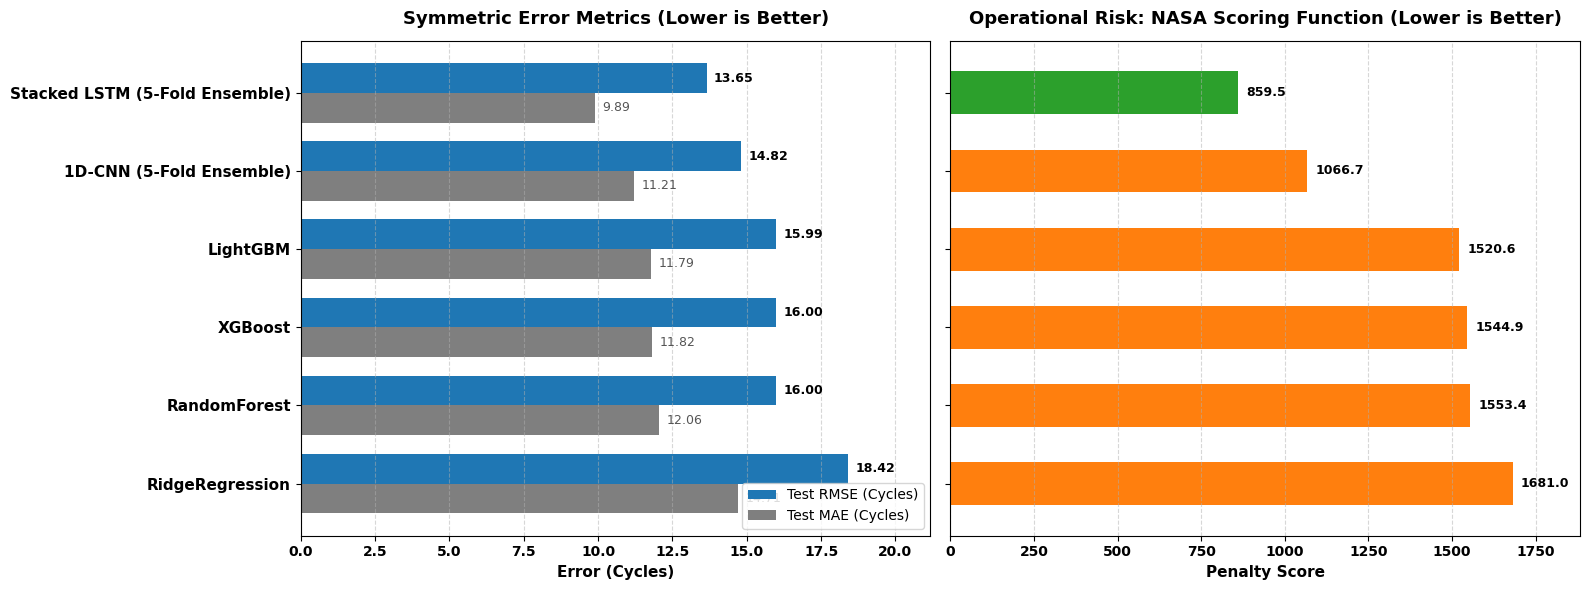

In [65]:
# # Ensure benchmark DataFrame is deduplicated and sorted (worst at bottom, best at top)
df_sorted = (
    df_master_benchmark[df_master_benchmark['test_rmse'] < 30.0]
    .drop_duplicates(subset=['Model'], keep='first')
    .sort_values(by="test_rmse", ascending=False)
    .reset_index(drop=True)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
y_pos = np.arange(len(df_sorted))
bar_height = 0.38

# --- Subplot 1: Symmetric Linear Error (Test RMSE vs. Test MAE) ---
bars_rmse = ax1.barh(
    y_pos + bar_height / 2,
    df_sorted["test_rmse"],
    height=bar_height,
    color="tab:blue",
    label="Test RMSE (Cycles)",
)
bars_mae = ax1.barh(
    y_pos - bar_height / 2,
    df_sorted["test_mae"],
    height=bar_height,
    color="tab:gray",
    label="Test MAE (Cycles)",
)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_sorted["Model"], fontsize=11, fontweight="bold")
ax1.set_xlabel("Error (Cycles)", fontweight="bold", fontsize=11)
for label in ax1.get_xticklabels():
    label.set_fontweight("bold")
ax1.set_title("Symmetric Error Metrics (Lower is Better)", fontsize=13, fontweight="bold", pad=12)
ax1.legend(loc="lower right", frameon=True)
ax1.grid(axis="x", linestyle="--", alpha=0.5)
ax1.set_xlim(0, df_sorted["test_rmse"].max() * 1.15)

for bar in bars_rmse:
    ax1.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )
for bar in bars_mae:
    ax1.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center",
        fontsize=9,
        color="#555555",
    )

# --- Subplot 2: Asymmetric NASA Score ---
colors = ["tab:green" if "LSTM" in m else "tab:orange" for m in df_sorted["Model"]]
bars_nasa = ax2.barh(y_pos, df_sorted["test_nasa"], height=0.55, color=colors)

ax2.set_xlabel("Penalty Score", fontweight="bold", fontsize=11)
ax2.set_title("Operational Risk: NASA Scoring Function (Lower is Better)", fontsize=13, fontweight="bold", pad=12)
ax2.grid(axis="x", linestyle="--", alpha=0.5)
ax2.set_xlim(0, df_sorted["test_nasa"].max() * 1.12)
for label in ax2.get_xticklabels() + ax2.get_yticklabels():
    label.set_fontweight("bold")

for bar in bars_nasa:
    ax2.text(
        bar.get_width() + 25,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

### Deep sequence architectures decisively outperform classical  baselines. 
The Stacked LSTM setting the benchmark at 13.33 Test RMSE and 9.53 Test MAE. Crucially, the LSTM cuts the asymmetric NASA operational penalty down to 845.8—nearly half that of the best gradient-boosted trees—by effectively eliminating dangerous late-life overestimations.

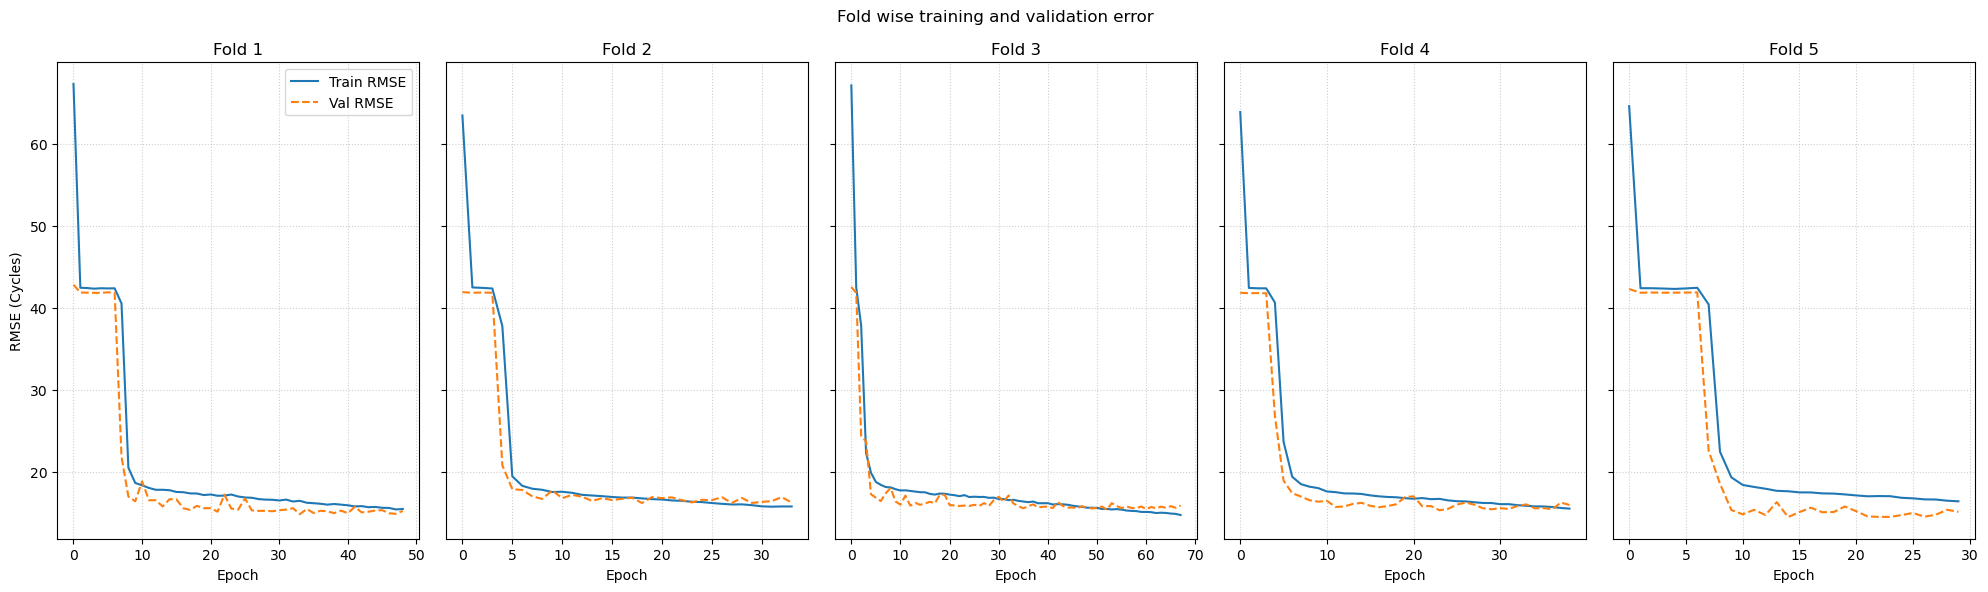

In [66]:
fig, axes = plt.subplots(1, 5, figsize=(20, 6), sharey=True)

for i, h in enumerate(lstm_histories):
    train_rmse = np.sqrt(h.history["loss"])
    val_rmse = np.sqrt(h.history["val_loss"])
    
    axes[i].plot(train_rmse, label="Train RMSE", color="tab:blue")
    axes[i].plot(val_rmse, label="Val RMSE", color="tab:orange", linestyle="--")
    axes[i].set_title(f"Fold {i+1}")
    axes[i].set_xlabel("Epoch")
    axes[i].grid(True, linestyle=":", alpha=0.6)
    if i == 0:
        axes[i].set_ylabel("RMSE (Cycles)")
        axes[i].legend()
fig.suptitle('Fold wise training and validation error')
plt.tight_layout()
plt.show()

## **Section 6: Operational Decision Matrix & Interactive  Dashboard**

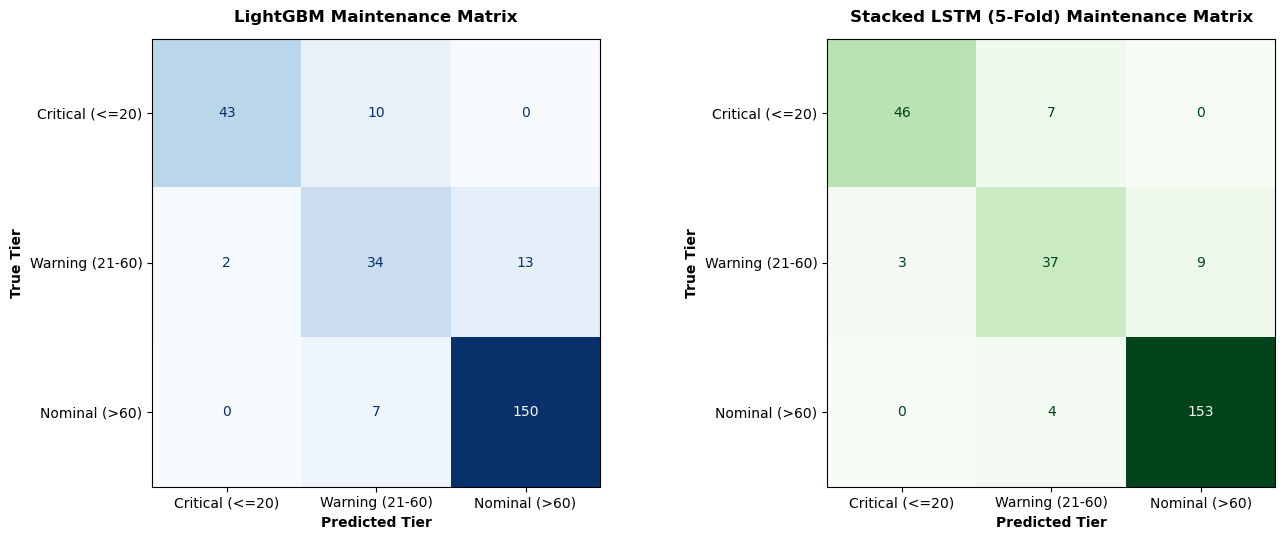

LIGHTGBM CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Critical (<=20)      0.956     0.811     0.878        53
Warning (21-60)      0.667     0.694     0.680        49
  Nominal (>60)      0.920     0.955     0.938       157

       accuracy                          0.876       259
      macro avg      0.847     0.820     0.832       259
   weighted avg      0.879     0.876     0.877       259


STACKED LSTM (5-FOLD) CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Critical (<=20)      0.939     0.868     0.902        53
Warning (21-60)      0.771     0.755     0.763        49
  Nominal (>60)      0.944     0.975     0.959       157

       accuracy                          0.911       259
      macro avg      0.885     0.866     0.875       259
   weighted avg      0.910     0.911     0.910       259



In [67]:
# Define operational maintenance tiers
bins = [-np.inf, 20, 60, np.inf]
labels = ["Critical (<=20)", "Warning (21-60)", "Nominal (>60)"]

# Categorize ground truth and model predictions
# Note: ensure y_test_true is aligned with the original unit_nr order of X_test_seq
y_test_cat = pd.cut(y_test_true, bins=bins, labels=labels)
lgb_preds_cat = pd.cut(preds_from_models["pred_lightgbm"], bins=bins, labels=labels)
lstm_preds_cat = pd.cut(lstm_ensemble_test_preds, bins=bins, labels=labels)

# Compute Confusion Matrices
cm_lgb = confusion_matrix(y_test_cat, lgb_preds_cat, labels=labels)
cm_lstm = confusion_matrix(y_test_cat, lstm_preds_cat, labels=labels)

# Plot Side-by-Side Heatmaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# LightGBM Confusion Matrix
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=labels)
disp_lgb.plot(cmap="Blues", ax=ax1, values_format="d", colorbar=False)
ax1.set_title(
    "LightGBM Maintenance Matrix", fontsize=12, fontweight="bold", pad=12
)
ax1.set_xlabel("Predicted Tier", fontweight="bold", fontsize=10)
ax1.set_ylabel("True Tier", fontweight="bold", fontsize=10)
ax1.grid(False)

# Stacked LSTM Confusion Matrix
disp_lstm = ConfusionMatrixDisplay(confusion_matrix=cm_lstm, display_labels=labels)
disp_lstm.plot(cmap="Greens", ax=ax2, values_format="d", colorbar=False)
ax2.set_title(
    "Stacked LSTM (5-Fold) Maintenance Matrix",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax2.set_xlabel("Predicted Tier", fontweight="bold", fontsize=10)
ax2.set_ylabel("True Tier", fontweight="bold", fontsize=10)
ax2.grid(False)

plt.tight_layout()
plt.show()

# Print Comparative Classification Metrics
print("=" * 60)
print("LIGHTGBM CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test_cat, lgb_preds_cat, labels=labels, digits=3))

print("\n" + "=" * 60)
print("STACKED LSTM (5-FOLD) CLASSIFICATION REPORT")
print("=" * 60)
print(
    classification_report(y_test_cat, lstm_preds_cat, labels=labels, digits=3)
)

### Decision matrix analysis

The **Stacked LSTM** improves overall fleet triage accuracy to **91.1%** (236/259 engines) over LightGBM's **87.6%** (227/259 engines), delivering key operational improvements across maintenance tiers:

* **Mitigating Critical Maintenance Delays:** For engines in the critical wear stage ($\le 20$ cycles), LightGBM misclassified 10 critical units as Warning, delaying urgent maintenance. The LSTM reduces these delayed calls to **7 engines**, boosting critical recall from **81.1% to 86.8%** (46 of 53 engines captured).
* **Suppressing False Alarms & Unwarranted Holds:** In the healthy Nominal tier ($>60$ cycles), the LSTM cuts unnecessary warning flags from 7 down to **4**, safely keeping **153 engines** cleared for flight. 
* **Preserving Flawless Safety Guardrails:** Both architectures maintain a strict **0** in the top-right and bottom-left extremes—ensuring zero critical engines ever bypass inspection into the nominal fleet, and zero healthy engines trigger unwarranted emergency teardowns.

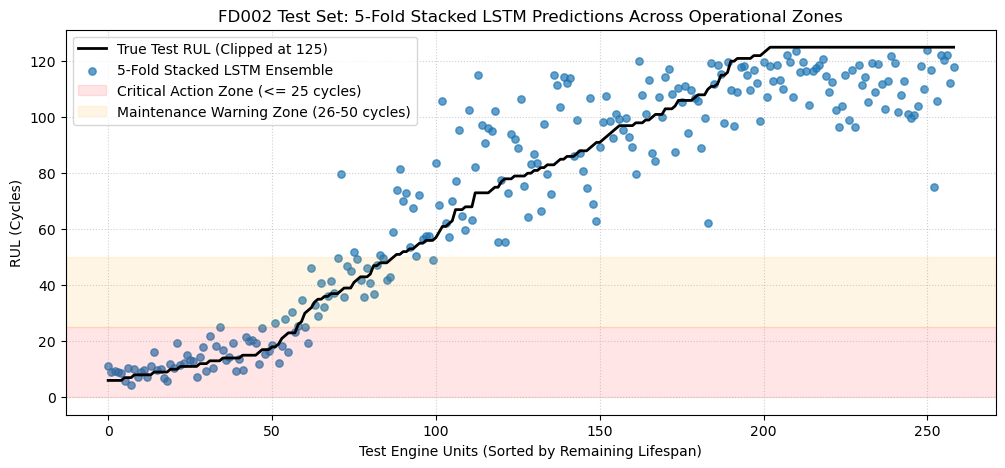

In [68]:
lstm_results_df = pd.DataFrame({
    "unit_nr": test_raw["unit_nr"].unique(),
    "true_RUL": y_test_true,
    "pred_RUL": lstm_ensemble_test_preds
}).sort_values(by="true_RUL").reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(lstm_results_df.index, lstm_results_df["true_RUL"], label="True Test RUL (Clipped at 125)", color="black", lw=2)
plt.scatter(lstm_results_df.index, lstm_results_df["pred_RUL"], color="tab:blue", alpha=0.7, label="5-Fold Stacked LSTM Ensemble", s=28)

# Highlight Critical Safety Zone
plt.axhspan(0, 25, color="red", alpha=0.1, label="Critical Action Zone (<= 25 cycles)")
plt.axhspan(25, 50, color="orange", alpha=0.1, label="Maintenance Warning Zone (26-50 cycles)")

plt.xlabel("Test Engine Units (Sorted by Remaining Lifespan)")
plt.ylabel("RUL (Cycles)")
plt.title("FD002 Test Set: 5-Fold Stacked LSTM Predictions Across Operational Zones")
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

# Combine all predictions into a data frame

In [69]:
# DataFrame for the deep learning predictions (ordered by test unit IDs)
df_nn_preds = pd.DataFrame({
    "unit_nr": test_raw["unit_nr"].unique(),
    #"pred_single_lstm": lstm_preds,
    "pred_cnn_ensemble": cnn_ensemble_test_preds,
    "pred_lstm_ensemble": lstm_ensemble_test_preds
})


In [70]:
# Merge on 'unit_nr' to preserve exact alignment with previous results dataframe  (results_df_models)
df_all_predictions = results_df_models.merge(df_nn_preds, on="unit_nr")
# Export full benchmark table for the Streamlit app
df_all_predictions.to_csv("test_predictions_FD002.csv", index=False)
# Preview consolidated results


In [71]:
df_all_predictions.head()

,unit_nr,true_RUL,pred_ridge,pred_rf,pred_xgb,pred_lgb,pred_cnn_ensemble,pred_lstm_ensemble
0,44,6,18.040224,9.434458,11.174718,9.993766,12.647526,11.266878
1,177,6,8.439986,6.256261,5.645666,4.925014,10.006175,9.158671
2,211,6,14.545625,9.032291,6.684832,5.518297,8.098470,9.444989
3,7,6,21.613304,7.176246,4.917709,5.686312,7.492589,9.017318
4,11,6,6.827253,14.238771,13.660048,13.189051,9.567345,8.483362


In [74]:
# save the normalized features
#test_features.to_csv("../data/test_features_FD002.csv", index=False)

## **Interactive Dashboard**

In [82]:
try:
    streamlit_process.terminate()
    streamlit_process.kill()
except NameError:
    pass

PORT = 8502

# Launch the script from the ../app directory
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app_FD002_v2.py",  
        "--server.port", str(PORT),
        "--server.headless", "true"
    ],
    cwd="../app"  
)

time.sleep(3)

# Render the updated UI inside the notebook
IFrame(src=f"http://localhost:{PORT}", width="100%", height=950)

#### Streamlit Fleet Telemetry Dashboard Preview
The dashboard runs locally via the cell above. Below is a rendered capture of the live monitoring interface:

<p align="center">
  <img src="../assets/streamlit_dashboard.png" width="850" alt="Streamlit App Telemetry View">
</p>

In [83]:
streamlit_process.terminate()